# 5장 1강: 배깅과 랜덤포레스트

## 실습 목표
이번 실습에서는 **Ames Housing** 데이터를 이용하여 배깅과 랜덤포레스트의 핵심 원리를 확인합니다.

- 하나의 의사결정나무와 여러 나무를 모은 배깅의 차이를 확인합니다.
- 배깅에서 여러 회귀 모델의 예측을 평균내는 이유를 이해합니다.
- 랜덤포레스트의 부트스트랩과 피처 무작위 선택 개념을 확인합니다.
- OOB Score와 Feature Importance를 확인합니다.
- 여러 나무를 평균낼 때 분산이 줄어드는 이유를 설명합니다.

> 교안에 나온 범위만 사용합니다.

## 실습 환경 / 데이터
- Python, pandas, numpy, matplotlib, scikit-learn
- 데이터: `Ames_Housing.csv`
- 예측 대상: `SalePrice`

사용 특성:
`OverallQual`, `GrLivArea`, `GarageCars`, `GarageArea`, `TotalBsmtSF`, `1stFlrSF`,
`2ndFlrSF`, `FullBath`, `TotRmsAbvGrd`, `YearBuilt`, `YearRemodAdd`, `Fireplaces`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
from sklearn.metrics import r2_score

house = pd.read_csv("Ames_Housing.csv")

features = [
    "OverallQual","GrLivArea","GarageCars","GarageArea",
    "TotalBsmtSF","1stFlrSF","2ndFlrSF","FullBath",
    "TotRmsAbvGrd","YearBuilt","YearRemodAdd","Fireplaces"
]

X = house[features]
y = house["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)
display(X.isna().sum().to_frame("missing"))

Train: (1168, 12)
Test: (292, 12)


,missing
OverallQual,0
GrLivArea,0
GarageCars,0
GarageArea,0
TotalBsmtSF,0
1stFlrSF,0
2ndFlrSF,0
FullBath,0
TotRmsAbvGrd,0
YearBuilt,0


# 필수 1. 하나의 나무와 Bagging 비교

## 문제 1. Decision Tree 하나를 학습하세요.
1. `DecisionTreeRegressor(random_state=42)` 사용
2. Train 학습
3. Train/Test 예측
4. Train R², Test R² 계산
5. 두 점수 차이 해석

In [2]:
tree = DecisionTreeRegressor(random_state=42).fit(X_train,y_train)
tree_train_r2 = r2_score(y_train,tree.predict(X_train))
tree_test_r2 = r2_score(y_test,tree.predict(X_test))
print(f'Train R2={tree_train_r2:.6f}, Test R2={tree_test_r2:.6f}, gap={tree_train_r2-tree_test_r2:.6f}')

Train R2=0.999901, Test R2=0.793873, gap=0.206027


### Q1. Train R²는 매우 높은데 Test R²가 더 낮다면 무엇을 의미하나요?

**답변:** Train R²=0.9999, Test R²=0.7939의 큰 간격은 Train의 잡음과 세부 패턴까지 학습한 과적합(고분산) 신호입니다. 일반화 성능이 낮아진 것이며 gap만으로 원인을 확정하지는 않습니다.

## 문제 2. Bagging을 적용하세요.
1. 기본 모델은 `DecisionTreeRegressor(random_state=42)`
2. `BaggingRegressor`
3. `n_estimators=50`
4. `random_state=42`
5. Test R² 계산
6. `max_features="sqrt`
7. Decision Tree 하나와 비교

In [3]:
# BaggingRegressor의 max_features는 정수·비율만 받으므로 sqrt는 기본 트리에 지정합니다.
bagging = BaggingRegressor(estimator=DecisionTreeRegressor(max_features='sqrt',random_state=42),
    n_estimators=50,bootstrap=True,random_state=42)
bagging.fit(X_train,y_train)
bagging_test_r2 = r2_score(y_test,bagging.predict(X_test))
display(pd.DataFrame({'Test R2':[tree_test_r2,bagging_test_r2]},index=['Decision Tree','Bagging']))

,Test R2
Decision Tree,0.793873
Bagging,0.891448


### Q2. 왜 각 나무를 서로 다른 부트스트랩 샘플로 학습하나요?

**답변:** 복원추출로 서로 다른 학습 샘플을 구성하면 나무의 오차가 완전히 같지 않게 되어 평균 예측의 분산을 낮출 수 있습니다.

# 필수 2. Random Forest의 OOB Score와 Feature Importance

## 문제 1. OOB Score를 확인하세요.
1. `RandomForestRegressor`
2. `n_estimators=100`
3. `bootstrap=True`
4. `oob_score=True`
5. `random_state=42`
6. Test R²와 `oob_score_` 출력

In [5]:
forest = RandomForestRegressor(n_estimators=100,bootstrap=True,oob_score=True,random_state=42)
forest.fit(X_train,y_train)
forest_test_r2 = r2_score(y_test,forest.predict(X_test))
print(f'Test R2={forest_test_r2:.6f}, OOB R2={forest.oob_score_:.6f}')
print('회귀 RandomForest의 기본 max_features=1.0은 모든 특성을 사용합니다. 분기 후보 특성도 무작위로 줄이려면 sqrt 등을 명시합니다.')

Test R2=0.890075, OOB R2=0.819045
회귀 RandomForest의 기본 max_features=1.0은 모든 특성을 사용합니다. 분기 후보 특성도 무작위로 줄이려면 sqrt 등을 명시합니다.


### Q3. OOB 샘플은 무엇인가요?

**답변:** 특정 나무의 부트스트랩 학습 샘플에 한 번도 뽑히지 않은 Train 관측값입니다. 각 관측값을 학습에 사용하지 않은 나무들로 예측하여 내부 검증에 활용합니다.

### Q4. OOB Score가 교차검증을 완전히 대체하나요?

**답변:** 완전히 대체하지는 않습니다. 이번 OOB R²=0.8190는 Train의 내부 일반화 추정치이고 Test R²=0.8901와 평가 데이터가 다릅니다. 시간·그룹 의존성이나 반복 튜닝에는 적절한 CV 및 독립 Test 평가가 필요합니다.

## 문제 2. Feature Importance를 확인하세요.
1. `feature_importances_` 사용
2. 특성명과 중요도 DataFrame 생성
3. 내림차순 정렬
4. 막대그래프
5. 가장 높은 중요도 특성 확인

,feature,importance
0,OverallQual,0.568166
1,GrLivArea,0.145061
4,TotalBsmtSF,0.059064
5,1stFlrSF,0.047472
6,2ndFlrSF,0.044405
3,GarageArea,0.033536
9,YearBuilt,0.031569
10,YearRemodAdd,0.022596
2,GarageCars,0.017413
8,TotRmsAbvGrd,0.012278


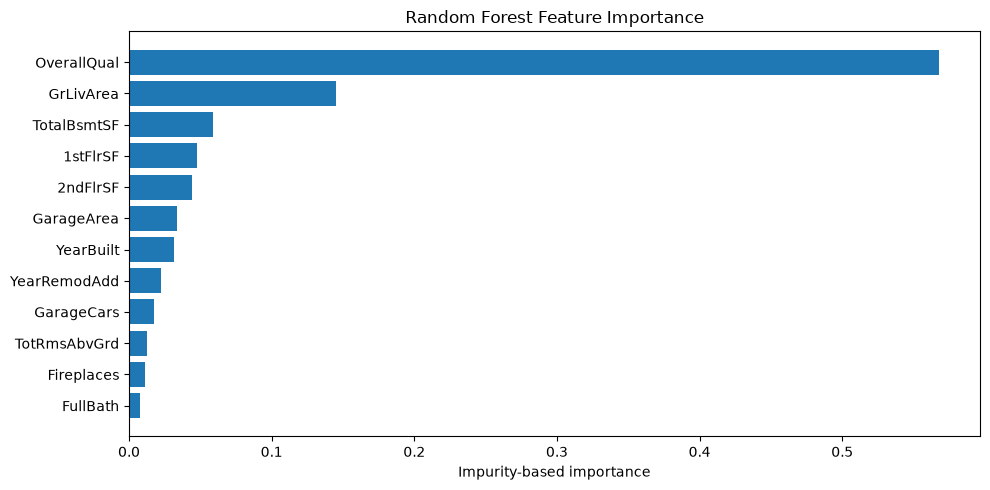

가장 높은 중요도: OverallQual


In [5]:
importance_df = pd.DataFrame({'feature':features,'importance':forest.feature_importances_}).sort_values('importance',ascending=False)
display(importance_df)
plt.figure(figsize=(10,5)); plt.barh(importance_df['feature'][::-1],importance_df['importance'][::-1])
plt.xlabel('Impurity-based importance'); plt.title('Random Forest Feature Importance')
plt.tight_layout(); plt.show()
print('가장 높은 중요도:',importance_df.iloc[0]['feature'])

### Q5. Feature Importance가 높다는 것이 그 변수가 주택가격의 원인이라는 뜻인가요?

**답변:** 아닙니다. 가장 높은 특성은 OverallQual이며, 이 모델에서 불순도 감소에 기여했다는 뜻입니다. 상관 특성 사이에서 중요도가 나뉘고 분할 후보 수에 따른 편향도 있어 인과 관계를 의미하지 않습니다.

# 과제 1. 나무 수와 예측 안정성 확인

`tree_counts = [1, 10, 50, 100]`을 사용하세요.

각 나무 수에서:
1. RandomForestRegressor 생성
2. `bootstrap=True`, `random_state=42`
3. Train 학습
4. Test R² 계산
5. DataFrame 정리
6. 나무 수에 따른 성능 변화 확인
7. 여러 예측의 평균과 분산 감소 관계 설명

,n_estimators,test_r2
0,1,0.742870
1,10,0.883597
2,50,0.889467
3,100,0.890075


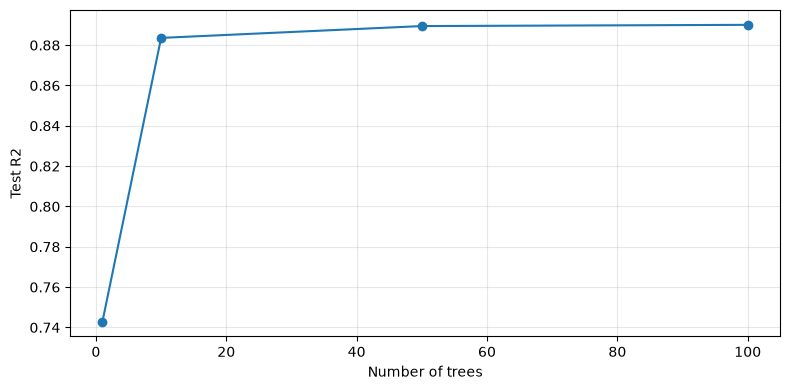

나무 수가 늘면 평균 예측이 안정화될 수 있지만 Test R2의 단조 증가나 분산 0은 보장되지 않습니다.


In [6]:
tree_counts = [1,10,50,100]
tree_count_rows = []
for count in tree_counts:
    count_model = RandomForestRegressor(n_estimators=count,bootstrap=True,random_state=42)
    count_model.fit(X_train,y_train)
    tree_count_rows.append({'n_estimators':count,'test_r2':r2_score(y_test,count_model.predict(X_test))})
tree_count_df = pd.DataFrame(tree_count_rows)
display(tree_count_df)
plt.figure(figsize=(8,4)); plt.plot(tree_count_df['n_estimators'],tree_count_df['test_r2'],'o-')
plt.xlabel('Number of trees'); plt.ylabel('Test R2'); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
print('나무 수가 늘면 평균 예측이 안정화될 수 있지만 Test R2의 단조 증가나 분산 0은 보장되지 않습니다.')

### Q6. 나무 수를 늘리면 왜 예측이 더 안정적으로 변하나요?

**답변:** 서로 다른 나무의 예측을 평균내면 개별 나무의 우연한 오차가 일부 상쇄됩니다.

### Q7. 나무 수를 계속 늘리면 분산이 무한히 0으로 줄어드나요?

**답변:** 아닙니다. 나무 사이의 오차가 상관되어 공통 오차가 남습니다. 동일한 분산 σ²와 쌍별 상관 ρ를 가정하면 평균의 분산은 σ²[ρ+(1−ρ)/B]이고, B를 늘려도 ρσ²에 수렴합니다. 데이터·특성의 한계와 편향도 사라지지 않습니다.

# 실습 마무리

1. 부트스트랩 샘플링은 어떤 방식인가요?  
-> 원본에서 복원추출하여 같은 샘플이 중복 선택될 수 있는 방식입니다.

2. Bagging 회귀에서는 여러 모델의 예측을 어떻게 합치나요?  
-> 여러 회귀 예측을 산술평균합니다.

3. Random Forest가 Bagging에 추가하는 무작위성은 무엇인가요?  
-> 일반적으로 각 분기에서 특성 후보를 무작위로 제한합니다.

4. OOB 샘플은 평균적으로 약 몇 %인가요?  
-> 약 36.8%입니다. 표본 수 n일 때 미선택 확률 (1−1/n)^n이 e⁻¹에 가까워집니다.

5. Feature Importance가 높다는 것은 무엇을 의미하나요?  
-> 학습된 모델의 분할에서 불순도 감소에 크게 기여했음을 뜻합니다. 인과적 영향은 아닙니다.

6. Bagging이 Decision Tree와 특히 잘 맞는 이유는 무엇인가요?  
-> 결정트리는 학습 데이터의 작은 변화에 민감한 고분산 모델이어서 평균화의 이점을 얻기 쉽습니다.